# EDA do churn · Vitaliza · grupo 11

**Pergunta:** o que separa os assinantes que saem dos que ficam?

**População:** 14.032 assinantes pagantes ativos no fim de 31/07/2026, sem contas internas.
**Rótulo:** `churn_60d` = a assinatura expirou nos 60 dias seguintes (até 29/09/2026).
**Regra:** toda variável usa só informação até 31/07/2026. A base vem de `src/base_analitica.py`;
as decisões de limpeza estão em `decisoes.md` e a conferência com o enunciado em `saidas/conferencia_enunciado.csv`.

Cada gráfico mostra o n de cada grupo. Grupos com menos de 100 assinantes ficam sinalizados e não sustentam conclusão.

In [1]:
import sys
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from situacao_assinantes import perdas_no_mes  # noqa: E402

PROCESSADOS = RAIZ / "dados" / "processados"
GRAFICOS = RAIZ / "saidas" / "graficos"
GRAFICOS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160)

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#c3c2b7"
SUPERFICIE, TEXTO, TEXTO_2, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": TEXTO_2, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRADE, "font.size": 10,
    "axes.titlesize": 12, "axes.titlelocation": "left", "axes.titlecolor": TEXTO,
})
N_MINIMO = 100

base = pd.read_csv(PROCESSADOS / "base_analitica.csv", parse_dates=["inicio", "fim"])
CHURN_BASE = base["churn_60d"].mean()
print(f"base analítica: {len(base)} assinantes, {base.shape[1]} colunas | churn_60d = {CHURN_BASE:.2%} "
      f"({base['churn_60d'].sum()} saídas)")

base analítica: 14032 assinantes, 52 colunas | churn_60d = 10.47% (1469 saídas)


In [2]:
def taxa(df, grupo):
    """Churn, n, saídas e parte do churn total por grupo."""
    t = df.groupby(grupo, observed=True)["churn_60d"].agg(n="size", saidas="sum", churn="mean")
    t["pct_base"] = t["n"] / len(df)
    t["pct_do_churn"] = t["saidas"] / df["churn_60d"].sum()
    return t


def barras(t, titulo, arquivo, rotulo_x="", cor=AZUL, destaque=None):
    """Barras de churn por grupo, com o n embaixo e a média da base tracejada."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    cores = [LARANJA if destaque is not None and i in destaque else cor for i in t.index]
    pequenos = t["n"] < N_MINIMO
    cores = [CINZA if p else c for c, p in zip(cores, pequenos)]
    pos = np.arange(len(t))
    ax.bar(pos, 100 * t["churn"], color=cores, width=0.7, edgecolor=SUPERFICIE, linewidth=2, zorder=2)
    for x, (c, n) in enumerate(zip(t["churn"], t["n"])):
        ax.text(x, 100 * c + 0.6, f"{100 * c:.1f}%".replace(".", ","), ha="center", va="bottom", fontsize=9,
                color=TEXTO, bbox=dict(facecolor=SUPERFICIE, edgecolor="none", pad=1), zorder=4)
    ax.axhline(100 * CHURN_BASE, color=TEXTO_2, linestyle="--", linewidth=1, zorder=3)
    ax.text(-0.45, 100 * CHURN_BASE + 0.4, f"base {100 * CHURN_BASE:.1f}%".replace(".", ","), ha="left", fontsize=8,
            color=TEXTO_2, bbox=dict(facecolor=SUPERFICIE, edgecolor="none", pad=1), zorder=4)
    ax.set_xticks(pos, [f"{i}\nn={n:,}".replace(",", ".") for i, n in zip(t.index, t["n"])], fontsize=8.5)
    ax.set_ylabel("Churn em 60 dias (%)")
    ax.set_xlabel(rotulo_x)
    ax.set_ylim(0, max(100 * t["churn"].max() * 1.18, 100 * CHURN_BASE * 1.5))
    ax.set_title(titulo)
    if pequenos.any():
        fig.text(0.01, 0.01, f"Em cinza: menos de {N_MINIMO} assinantes, não sustenta conclusão.", fontsize=7.5, color=TEXTO_2)
    fig.tight_layout()
    fig.savefig(GRAFICOS / arquivo, dpi=150)
    plt.show()


def auc(score, alvo):
    """AUC de uma variável sozinha (Mann-Whitney). Devolve o maior entre AUC e 1-AUC."""
    ok = score.notna()
    s, y = score[ok], alvo[ok]
    r = s.rank()
    n1, n0 = y.sum(), (1 - y).sum()
    a = (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    return max(a, 1 - a), ("maior → mais churn" if a >= 0.5 else "menor → mais churn"), ok.mean()

## 1. O que a média esconde: plano × tempo de casa

A média de churn esconde grupos com riscos muito diferentes. Primeiro corte: plano e tempo de casa,
as duas variáveis de ciclo de vida.

faixa_casa,0–1 mês,2–5 meses,6–11 meses,12–23 meses,24+ meses
plano,,,,,
anual,0.5% (n=626),0.0% (n=1627),15.4% (n=2462),6.8% (n=2354),6.8% (n=1217)
mensal,17.9% (n=1014),18.9% (n=1637),14.9% (n=1354),10.1% (n=1209),5.3% (n=532)


,n,saidas,churn,pct_base,pct_do_churn
plano,,,,,
anual,8286,625,7.5%,59.1%,42.5%
mensal,5746,844,14.7%,40.9%,57.5%


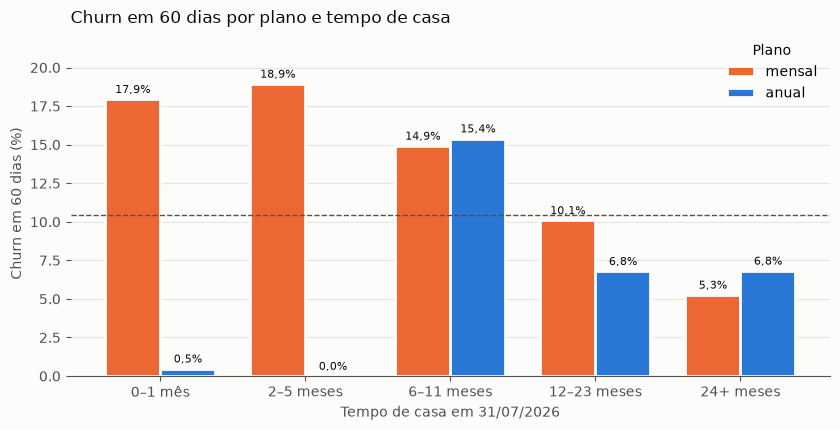

In [3]:
faixas = [-1, 1, 5, 11, 23, 10_000]
nomes = ["0–1 mês", "2–5 meses", "6–11 meses", "12–23 meses", "24+ meses"]
base["faixa_casa"] = pd.cut(base["tempo_casa_meses"], faixas, labels=nomes)
cruz = base.pivot_table(index="plano", columns="faixa_casa", values="churn_60d", aggfunc=["mean", "size"], observed=True)
tabela = cruz["mean"].map(lambda v: f"{100 * v:.1f}%") + " (n=" + cruz["size"].astype(str) + ")"
display(tabela)
display(taxa(base, "plano").style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(8.5, 4.4))
largura = 0.38
pos = np.arange(len(nomes))
for i, (plano, cor) in enumerate([("mensal", LARANJA), ("anual", AZUL)]):
    vals = cruz["mean"].loc[plano].reindex(nomes)
    ns = cruz["size"].loc[plano].reindex(nomes)
    x = pos + (i - 0.5) * largura
    ax.bar(x, 100 * vals, width=largura, color=cor, edgecolor=SUPERFICIE, linewidth=2, zorder=2, label=plano)
    for xi, v, n in zip(x, vals, ns):
        if pd.notna(v):
            ax.text(xi, 100 * v + 0.4, f"{100 * v:.1f}%".replace(".", ","), ha="center", fontsize=8, color=TEXTO)
ax.axhline(100 * CHURN_BASE, color=TEXTO_2, linestyle="--", linewidth=1)
ax.set_ylim(0, 100 * cruz["mean"].max().max() * 1.18)
ax.set_xticks(pos, nomes)
ax.set_ylabel("Churn em 60 dias (%)")
ax.set_xlabel("Tempo de casa em 31/07/2026")
ax.legend(frameon=False, title="Plano")
ax.set_title("Churn em 60 dias por plano e tempo de casa")
fig.tight_layout()
fig.savefig(GRAFICOS / "01_churn_plano_tempo_casa.png", dpi=150)
plt.show()

**Leitura.** O churn de 10,5% esconde grupos de 0% a 19%. No **mensal**, o risco cai com o tempo de casa: 17,9% a 18,9% até 5 meses e 5,3% com 24 meses ou mais. No **anual**, o padrão é outro: quase ninguém sai até 5 meses (0,0% a 0,5%), porque a renovação não cai na janela, e o pico é em 6 a 11 meses (15,4%), quando a renovação cai na janela. O mensal é 41% da base e 57% do churn. Para o anual, o que importa é a data da renovação, não o tempo de casa.

## 2. Canal de cobrança: loja ou site

,n,saidas,churn,pct_base,pct_do_churn
canal_cobranca,,,,,
web_cartao,2867,342,11.9%,20.4%,23.3%
google_play,4712,491,10.4%,33.6%,33.4%
web_pix,1334,137,10.3%,9.5%,9.3%
app_store,5119,499,9.7%,36.5%,34.0%


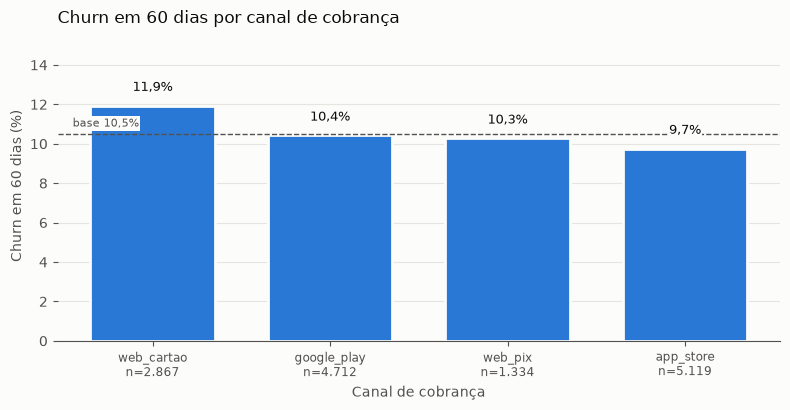

plano,anual,mensal
canal_cobranca,,
app_store,7.1%,13.4%
google_play,7.9%,14.4%
web_cartao,8.0%,18.1%
web_pix,6.8%,13.9%


In [4]:
t_canal = taxa(base, "canal_cobranca").sort_values("churn", ascending=False)
display(t_canal.style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
barras(t_canal, "Churn em 60 dias por canal de cobrança", "02_churn_canal.png", "Canal de cobrança")
display(base.pivot_table(index="canal_cobranca", columns="plano", values="churn_60d", aggfunc="mean").map(lambda v: f"{100 * v:.1f}%"))

**Leitura.** O canal separa pouco: de 9,7% (App Store) a 11,9% (cartão). A diferença se concentra no mensal pago com cartão (18,1%, contra 13,4% a 14,4% nos outros canais do mensal). Como a oferta na hora do cancelamento só alcança quem paga pelo site, cerca de 70% da base precisa ser abordada antes, a partir dos sinais de uso.

## 3. Comportamento de uso (mai–jul/2026)

Uso médio por mês nos meses em que a pessoa já assinava, e a queda de treinos em julho
(julho abaixo da metade da média de maio e junho).

,n,saidas,churn,pct_base,pct_do_churn
faixa_treinos,,,,,
0,1253,276,22.0%,8.9%,18.8%
até 2,3493,437,12.5%,24.9%,29.7%
2–4,2144,195,9.1%,15.3%,13.3%
4–8,2824,265,9.4%,20.1%,18.0%
8+,4318,296,6.9%,30.8%,20.1%


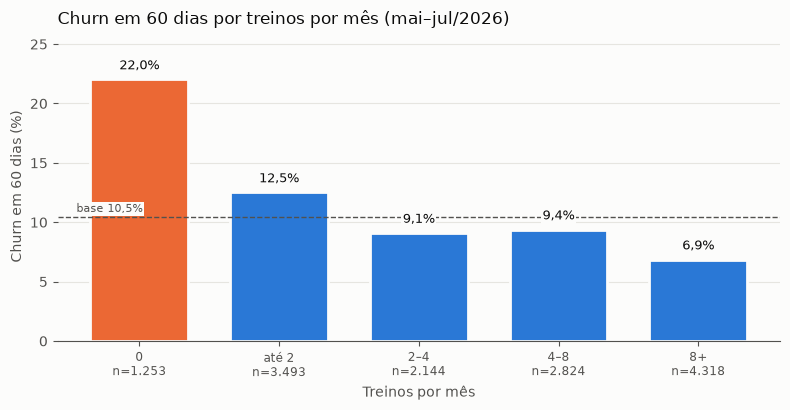

,n,saidas,churn,pct_base,pct_do_churn
faixa_sessoes,,,,,
"(-0.001, 2.33]",2937,529,18.0%,20.9%,36.0%
"(2.33, 4.67]",2870,280,9.8%,20.5%,19.1%
"(4.67, 8.67]",2687,250,9.3%,19.1%,17.0%
"(8.67, 14.0]",2772,210,7.6%,19.8%,14.3%
"(14.0, 64.33]",2766,200,7.2%,19.7%,13.6%


,n,saidas,churn,pct_base,pct_do_churn
queda,,,,,
caiu em julho,2418,417,17.2%,19.6%,32.5%
não caiu,9947,866,8.7%,80.4%,67.5%


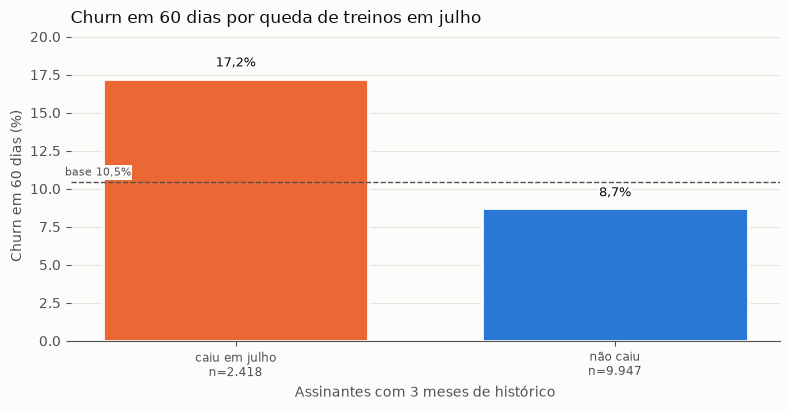

,n,saidas,churn,pct_base,pct_do_churn
perfil_treino,,,,,
ar livre,7521,755,10.0%,53.6%,51.4%
misto,141,20,14.2%,1.0%,1.4%
não treinou,1253,276,22.0%,8.9%,18.8%
vídeo,5117,418,8.2%,36.5%,28.5%


In [5]:
base["faixa_treinos"] = pd.cut(base["treinos_mes"], [-0.01, 0, 2, 4, 8, 1000],
                               labels=["0", "até 2", "2–4", "4–8", "8+"])
t_treinos = taxa(base, "faixa_treinos")
display(t_treinos.style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
barras(t_treinos, "Churn em 60 dias por treinos por mês (mai–jul/2026)", "03_churn_treinos_mes.png",
       "Treinos por mês", destaque=["0"])

base["faixa_sessoes"] = pd.qcut(base["sessoes_mes"], 5, duplicates="drop")
display(taxa(base, "faixa_sessoes").style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))

com3 = base[base["meses_observados"] == 3].copy()
com3["queda"] = com3["queda_treinos"].map({1.0: "caiu em julho", 0.0: "não caiu"})
t_queda = taxa(com3, "queda")
display(t_queda.style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
barras(t_queda, "Churn em 60 dias por queda de treinos em julho", "04_churn_queda_uso.png",
       "Assinantes com 3 meses de histórico", destaque=["caiu em julho"])

base["perfil_treino"] = np.select(
    [base["treinos_3m"] == 0, base["pct_ar_livre"] >= 0.7, base["pct_ar_livre"] <= 0.3],
    ["não treinou", "ar livre", "vídeo"], default="misto")
display(taxa(base, "perfil_treino").style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))

**Leitura.** Uso baixo acompanha a saída: quem não treinou em mai–jul sai 22,0%, contra 6,9% de quem treina 8 vezes ou mais por mês. O quinto com menos sessões no app sai 18,0%. Quem teve queda de treinos em julho sai 17,2%, contra 8,7%. Mas há um limite: entre quem está com a renovação ligada, o churn fica entre 5,5% e 6,8% em todas as faixas de treino. O uso baixo anda junto com a decisão de desligar a renovação, e o efeito passa em boa parte por ela. Treino ao ar livre (10,0%) e em vídeo (8,2%) diferem pouco.

## 4. Ciclo e sinais de assinatura (até 31/07/2026)

A renovação desligada é o primeiro aviso da loja: a pessoa continua assinante até o fim do período pago.
É informação anterior à saída (não é vazamento), mas mede uma decisão já tomada, não um comportamento.

,n,saidas,churn,pct_base,pct_do_churn
renovacao_ref,,,,,
desligada,2347,758,32.3%,16.7%,51.6%
ligada,11685,711,6.1%,83.3%,48.4%


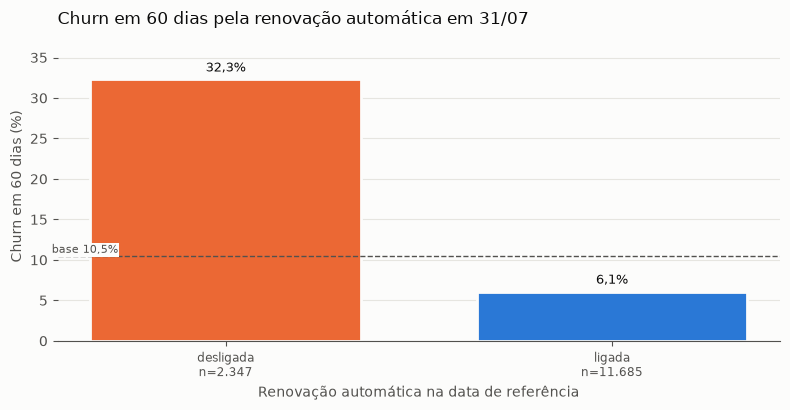

mean                size       
renovacao_ref desligada    ligada desligada ligada
plano                                             
anual          0.249289  0.016030      2110   6176
mensal         0.978903  0.111091       237   5509

,n,saidas,churn,pct_base,pct_do_churn
veio_de_trial,,,,,
0,1550,86,5.5%,11.0%,5.9%
1,12482,1383,11.1%,89.0%,94.1%


,n,saidas,churn,pct_base,pct_do_churn
cancelamento_web_ate_ref,,,,,
0,13668,1352,9.9%,97.4%,92.0%
1,364,117,32.1%,2.6%,8.0%


,n,saidas,churn,pct_base,pct_do_churn
carencia_ate_ref,,,,,
0,14010,1447,10.3%,99.8%,98.5%
1,22,22,100.0%,0.2%,1.5%


,n,saidas,churn,pct_base,pct_do_churn
teve_recusa,,,,,
sem recusa,13248,1358,10.3%,94.4%,92.4%
teve recusa,784,111,14.2%,5.6%,7.6%


,saídas
tipo_saida,
nao_informado,990
voluntaria,414
falha_pagamento,63
chargeback_reembolso,2


In [6]:
base["renovacao_ref"] = base["renovacao_desligada_ref"].map({1: "desligada", 0: "ligada"})
t_renov = taxa(base, "renovacao_ref")
display(t_renov.style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
barras(t_renov, "Churn em 60 dias pela renovação automática em 31/07", "05_churn_renovacao.png",
       "Renovação automática na data de referência", destaque=["desligada"])
display(base.pivot_table(index="plano", columns="renovacao_ref", values="churn_60d", aggfunc=["mean", "size"]))
for col in ["veio_de_trial", "cancelamento_web_ate_ref", "carencia_ate_ref"]:
    display(taxa(base, col).style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
base["teve_recusa"] = (base["recusas_ate_ref"] > 0).map({True: "teve recusa", False: "sem recusa"})
display(taxa(base, "teve_recusa").style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
display(base.loc[base["churn_60d"] == 1, "tipo_saida"].value_counts().to_frame("saídas"))

**Leitura.** A renovação desligada é o sinal mais forte da base: 32,3% de churn, contra 6,1% com a renovação ligada, e ela cobre 758 das 1.469 saídas (52%). No mensal, 97,9% de quem desligou sai na janela. No anual, 24,9% (a saída só acontece na renovação). Cancelar pelo site antes de 31/07 dá 32,1%. Ter tido recusa de cobrança dá 14,2%; só 63 saídas (4%) foram por falha de pagamento. Atenção: 990 saídas (67%) não têm motivo registrado. Esse sinal é uma decisão já tomada, então serve para priorizar o contato, não para descrever o comportamento.

## 5. Entrada: canal de aquisição, cupom, relógio e demografia

Idade e sexo só descrevem (LGPD, art. 6º, IX): não são gatilho de ação. O gêmeo demográfico
compara o churn de um segmento com o de pessoas de mesmo perfil de cadastro sem o comportamento.

,n,saidas,churn,pct_base,pct_do_churn
canal_aquisicao,,,,,
influenciador,2147,259,12.1%,15.3%,17.6%
meta_ads,2369,253,10.7%,16.9%,17.2%
organico,4491,466,10.4%,32.0%,31.7%
google_ads,1493,149,10.0%,10.6%,10.1%
parceria_corporativa,1382,135,9.8%,9.8%,9.2%
indicacao,2150,207,9.6%,15.3%,14.1%


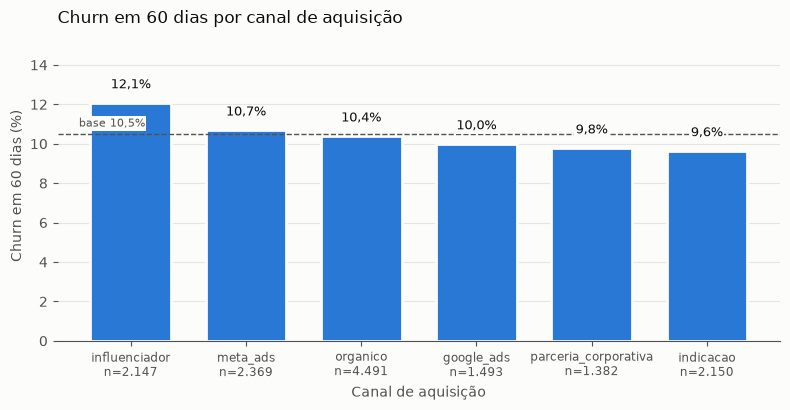

,n,saidas,churn,pct_base,pct_do_churn
cupom_influenciador,,,,,
0,13114,1417,10.8%,93.5%,96.5%
1,918,52,5.7%,6.5%,3.5%


,n,saidas,churn,pct_base,pct_do_churn
relogio_conectado,,,,,
apple_watch,2623,294,11.2%,18.7%,20.0%
garmin,2738,287,10.5%,19.5%,19.5%
nenhum,8671,888,10.2%,61.8%,60.4%


,n,saidas,churn,pct_base,pct_do_churn
nivel,,,,,
avancado,2308,237,10.3%,16.4%,16.1%
iniciante,5086,542,10.7%,36.2%,36.9%
intermediario,5640,589,10.4%,40.2%,40.1%


,n,saidas,churn,pct_base,pct_do_churn
sexo,,,,,
F,7005,731,10.4%,49.9%,49.8%
M,6366,670,10.5%,45.4%,45.6%


,n,saidas,churn,pct_base,pct_do_churn
faixa_idade,,,,,
até 25,95,9,9.5%,0.7%,0.6%
26–35,1808,196,10.8%,12.9%,13.3%
36–45,4289,454,10.6%,30.6%,30.9%
46–55,3970,419,10.6%,28.3%,28.5%
56+,3021,303,10.0%,21.5%,20.6%


In [7]:
t_aq = taxa(base, "canal_aquisicao").sort_values("churn", ascending=False)
display(t_aq.style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
barras(t_aq, "Churn em 60 dias por canal de aquisição", "06_churn_aquisicao.png", "Canal de aquisição")
for col in ["cupom_influenciador", "relogio_conectado", "nivel", "sexo"]:
    display(taxa(base, col).style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
base["faixa_idade"] = pd.cut(base["idade_ref"], [0, 25, 35, 45, 55, 100], labels=["até 25", "26–35", "36–45", "46–55", "56+"])
display(taxa(base, "faixa_idade").style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
base["gap_frequencia"] = base["dias_semana_pretendidos"] * 4.3 - base["treinos_mes"]

**Leitura.** A entrada separa pouco. Influenciador tem o maior churn (12,1%), contra 9,6% a 10,7% nos outros canais. O cupom de influenciador tem churn baixo (5,7%) porque a primeira anuidade ainda não venceu. Relógio, nível declarado, sexo e idade praticamente não separam (todos entre 9,5% e 11,2%). Diferente da base usada em aula, aqui a demografia não prevê a saída. E ela não seria gatilho de ação de qualquer forma.

## 6. Quanto cada variável separa quem sai

AUC de cada variável sozinha (0,50 = acaso; 1,00 = separa perfeitamente). Para categorias, o score é
o churn da própria categoria (medido na mesma base, então levemente otimista).

,variavel,tipo,auc,direcao,cobertura
0,renovacao_desligada_ref,numérica,0.695,maior → mais churn,1.000
1,treinos_m1,numérica,0.636,menor → mais churn,1.000
2,dias_ativos_3m,numérica,0.619,menor → mais churn,1.000
3,treinos_mes,numérica,0.612,menor → mais churn,1.000
4,minutos_3m,numérica,0.611,menor → mais churn,1.000
5,sessoes_mes,numérica,0.610,menor → mais churn,1.000
6,valor_mensal_liquido,numérica,0.600,maior → mais churn,1.000
7,plano,categoria,0.592,churn da categoria,1.000
8,queda_treinos,numérica,0.572,maior → mais churn,0.881
9,gap_frequencia,numérica,0.560,maior → mais churn,0.899


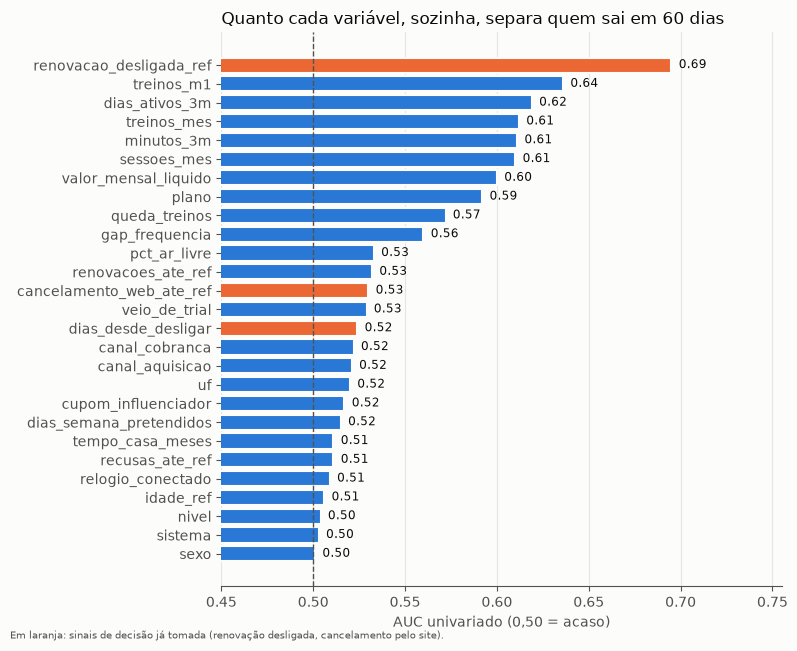

spearman
treinos_mes    sessoes_mes         0.99
               dias_ativos_3m      0.97
dias_ativos_3m minutos_3m          0.96
sessoes_mes    dias_ativos_3m      0.96
treinos_mes    minutos_3m          0.94
sessoes_mes    minutos_3m          0.93
treinos_mes    treinos_m1          0.91
sessoes_mes    treinos_m1          0.91
treinos_m1     dias_ativos_3m      0.88
               minutos_3m          0.85

In [8]:
numericas = ["tempo_casa_meses", "treinos_mes", "sessoes_mes", "treinos_m1", "dias_ativos_3m", "minutos_3m",
             "pct_ar_livre", "queda_treinos", "renovacoes_ate_ref", "renovacao_desligada_ref", "dias_desde_desligar",
             "veio_de_trial", "cancelamento_web_ate_ref", "recusas_ate_ref", "valor_mensal_liquido",
             "cupom_influenciador", "idade_ref", "dias_semana_pretendidos", "gap_frequencia"]
categoricas = ["plano", "canal_cobranca", "canal_aquisicao", "relogio_conectado", "sistema", "nivel", "sexo", "uf"]
linhas = []
for c in numericas:
    a, direcao, cobertura = auc(base[c].astype(float), base["churn_60d"])
    linhas.append((c, "numérica", round(a, 3), direcao, round(cobertura, 3)))
for c in categoricas:
    score = base.groupby(c)["churn_60d"].transform("mean").where(base[c].notna() & (base[c] != ""))
    a, _, cobertura = auc(score, base["churn_60d"])
    linhas.append((c, "categoria", round(a, 3), "churn da categoria", round(cobertura, 3)))
ranking = pd.DataFrame(linhas, columns=["variavel", "tipo", "auc", "direcao", "cobertura"]).sort_values("auc", ascending=False)
display(ranking.reset_index(drop=True))
ranking.to_csv(RAIZ / "saidas" / "eda_auc_univariado.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 6.5))
r = ranking.iloc[::-1]
cores = [LARANJA if v in {"renovacao_desligada_ref", "dias_desde_desligar", "cancelamento_web_ate_ref"} else AZUL
         for v in r["variavel"]]
ax.barh(r["variavel"], r["auc"], color=cores, edgecolor=SUPERFICIE, linewidth=1.5, zorder=2)
for y, v in enumerate(r["auc"]):
    ax.text(v + 0.004, y, f"{v:.2f}", va="center", fontsize=8.5, color=TEXTO)
ax.axvline(0.5, color=TEXTO_2, linestyle="--", linewidth=1)
ax.set_xlim(0.45, max(r["auc"]) + 0.06)
ax.grid(axis="x", color=GRADE)
ax.grid(axis="y", visible=False)
ax.set_xlabel("AUC univariado (0,50 = acaso)")
ax.set_title("Quanto cada variável, sozinha, separa quem sai em 60 dias")
fig.text(0.01, 0.01, "Em laranja: sinais de decisão já tomada (renovação desligada, cancelamento pelo site).",
         fontsize=7.5, color=TEXTO_2)
fig.tight_layout()
fig.savefig(GRAFICOS / "07_auc_univariado.png", dpi=150)
plt.show()

corr = base[[c for c in numericas if c != "dias_desde_desligar"]].astype(float).corr(method="spearman")
pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
display(pares.head(10).round(2).to_frame("spearman"))

**Leitura.** Sozinha, nenhuma variável separa muito: a maior AUC é a da renovação desligada (0,69). Depois vêm as de uso: treinos em julho (0,64), dias ativos (0,62), treinos por mês (0,61), sessões (0,61). Depois, valor mensal (0,60) e plano (0,59). Demografia, relógio e nível ficam em torno de 0,50. As variáveis de uso são quase a mesma informação (correlação de 0,85 a 0,99): para o k-means, basta uma ou duas delas (por exemplo, treinos por mês e queda em julho).

## 7. Por que o churn subiu em 2026: série mensal por plano e canal

Churn mensal da empresa (perdas no mês ÷ ativos no início do mês), reconstruído pelos eventos.
O reajuste do mensal (R$ 34,90 → R$ 39,90) foi em 01/03/2026.

ano,2025,2026
grupo,,
anual,2.6%,3.3%
loja,5.4%,6.3%
mensal,9.0%,10.8%
site,6.2%,7.3%
total,5.6%,6.6%


mensal: média jan–fev/2026 = 10.1% | mar–set/2026 = 11.0% | 2025 = 9.0%


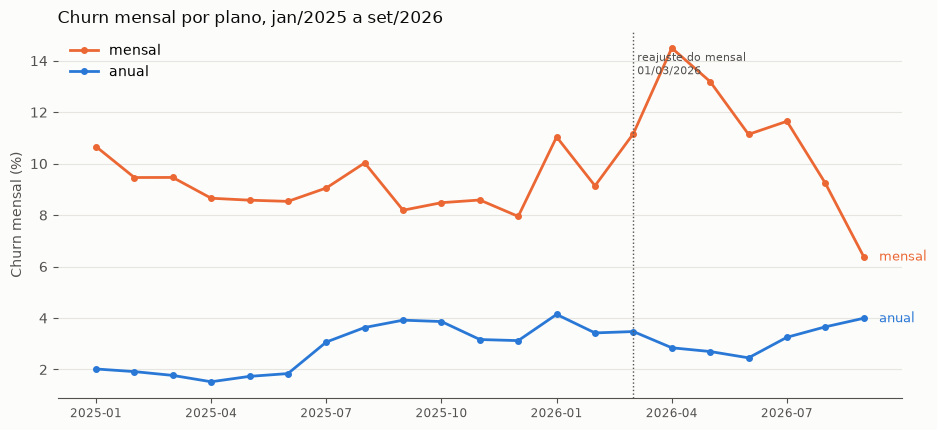

In [9]:
periodos = pd.read_csv(PROCESSADOS / "assinaturas_periodos.csv", parse_dates=["inicio", "fim"])
periodos["loja_ou_site"] = np.where(periodos["canal_cobranca"].str.startswith("web"), "site", "loja")
meses = pd.period_range("2025-01", "2026-09", freq="M").astype(str)
serie = []
for m in meses:
    for chave, grupo in [("plano", "mensal"), ("plano", "anual"), ("loja_ou_site", "loja"), ("loja_ou_site", "site")]:
        b, p = perdas_no_mes(periodos[periodos[chave] == grupo], m)
        serie.append((m, chave, grupo, b, p, p / b))
    b, p = perdas_no_mes(periodos, m)
    serie.append((m, "total", "total", b, p, p / b))
serie = pd.DataFrame(serie, columns=["mes", "corte", "grupo", "ativos_inicio", "perdas", "churn"])
serie.to_csv(RAIZ / "saidas" / "eda_serie_churn_mensal.csv", index=False)
resumo = serie.assign(ano=serie["mes"].str[:4]).groupby(["grupo", "ano"])["churn"].mean().unstack().map(lambda v: f"{100 * v:.1f}%")
display(resumo)
mensal = serie[serie["grupo"] == "mensal"].set_index("mes")["churn"]
print("mensal: média jan–fev/2026 = {:.1%} | mar–set/2026 = {:.1%} | 2025 = {:.1%}".format(
    mensal.loc["2026-01":"2026-02"].mean(), mensal.loc["2026-03":"2026-09"].mean(), mensal.loc["2025-01":"2025-12"].mean()))

fig, ax = plt.subplots(figsize=(9.5, 4.4))
for grupo, cor in [("mensal", LARANJA), ("anual", AZUL)]:
    s = serie[serie["grupo"] == grupo]
    ax.plot(s["mes"], 100 * s["churn"], color=cor, linewidth=2, marker="o", markersize=4, label=grupo)
    ax.text(len(meses) - 0.6, 100 * s["churn"].iloc[-1], grupo, color=cor, va="center", fontsize=9)
ax.axvline(meses.get_loc("2026-03"), color=TEXTO_2, linestyle=":", linewidth=1)
ax.text(meses.get_loc("2026-03") + 0.1, ax.get_ylim()[1] * 0.95, "reajuste do mensal\n01/03/2026", fontsize=8, color=TEXTO_2, va="top")
ax.set_xticks(range(0, len(meses), 3), meses[::3], fontsize=8.5)
ax.set_ylabel("Churn mensal (%)")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Churn mensal por plano, jan/2025 a set/2026")
fig.tight_layout()
fig.savefig(GRAFICOS / "08_serie_churn_plano.png", dpi=150)
plt.show()

**Leitura.** O churn subiu em 2026 em todos os cortes: mensal de 9,0% para 10,8%, anual de 2,6% para 3,3%, loja de 5,4% para 6,3% e site de 6,2% para 7,3%. No mensal, há um **pico logo depois do reajuste**: 14,5% em abril (932 perdas) e 13,2% em maio, contra 8% a 9% no fim de 2025. O pico é compatível com o reajuste: quem renovou a R$ 39,90 em março desligou e expirou em abril e maio. Depois o churn volta a cair (6,4% em setembro). Mas o reajuste não explica tudo: jan/2026 já tinha 11,0%, antes de março, e o anual, que não teve reajuste, sobe desde jul/2025. Cruzamento aponta suspeitos, não prova causa.

## 8. Controle: a campanha de 10/08 distorce o rótulo?

A campanha caiu dentro da janela. Se um grupo que recebeu mensagem sai muito menos que o controle,
o churn medido na janela fica abaixo do que seria sem campanha. Não é a análise da campanha (semana 10),
só um controle. Os 254 sem grupo saíram antes do sorteio.

In [10]:
camp = base[base["grupo_campanha"].notna() & (base["fim"].isna() | (base["fim"] >= "2026-08-10"))]
t_camp = taxa(camp, "grupo_campanha").reindex(["controle", "desafio", "cupom", "conteudo"])
display(t_camp.style.format({"churn": "{:.1%}", "pct_base": "{:.1%}", "pct_do_churn": "{:.1%}"}))
controle = t_camp.loc["controle", "churn"]
for g in ["desafio", "cupom", "conteudo"]:
    p1, n1 = t_camp.loc[g, "churn"], t_camp.loc[g, "n"]
    p0, n0 = controle, t_camp.loc["controle", "n"]
    ep = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    print(f"{g}: {100 * (p1 - p0):+.1f} pp contra o controle (IC 95% ±{100 * 1.96 * ep:.1f} pp)")

,n,saidas,churn,pct_base,pct_do_churn
grupo_campanha,,,,,
controle,3497,339,9.7%,25.4%,27.9%
desafio,3438,298,8.7%,25.0%,24.5%
cupom,3381,265,7.8%,24.5%,21.8%
conteudo,3462,313,9.0%,25.1%,25.8%


desafio: -1.0 pp contra o controle (IC 95% ±1.4 pp)
cupom: -1.9 pp contra o controle (IC 95% ±1.3 pp)
conteudo: -0.7 pp contra o controle (IC 95% ±1.4 pp)


**Leitura.** O cupom reduziu o churn na janela em 1,9 ponto contra o controle (intervalo de 95%: ±1,3). Desafio (−1,0) e conteúdo (−0,7) não se distinguem do controle. Para a EDA, isso significa que o rótulo dos grupos tratados ficou um pouco abaixo do que seria sem campanha. A diferença é pequena e vai para as limitações. A análise completa da campanha (uplift) fica para a semana 10.

## 9. Hipóteses: o que sobreviveu e o que caiu

In [11]:
hipoteses = pd.read_csv(RAIZ / "saidas" / "eda_hipoteses.csv") if (RAIZ / "saidas" / "eda_hipoteses.csv").exists() else None
display(hipoteses)

,id,galho,hipotese,metrica,cai_se,resultado,veredito
0,H1,ciclo e contrato,Assinantes do plano mensal saem mais que os do...,churn_60d por plano,diferença menor que 2 pp,mensal 14.7% (n=5.746) x anual 7.5% (n=8.286);...,sobreviveu
1,H2,ciclo e contrato,Quem tem pouco tempo de casa sai mais,churn_60d por plano x tempo de casa,0–5 meses não fica acima de 12+ meses,mensal: 17.9–18.9% em 0–5 meses x 5.3–10.1% em...,sobreviveu no mensal; no anual o risco é a dat...
2,H3,uso,Uso baixo precede a saída,churn_60d por treinos/mês e sessões/mês,quem não treina não fica acima de 1.5x a base,0 treinos/mês 22.0% (n=1.253) x 8+ 6.9%; quint...,sobreviveu; mas com renovação ligada o uso qua...
3,H4,uso,Queda de treinos em julho antecede a saída,churn_60d por queda_treinos (julho < metade da...,diferença menor que 3 pp,caiu em julho 17.2% (n=2.418) x 8.7%,sobreviveu
4,H5,ciclo e contrato,A renovação desligada é o sinal mais forte de ...,churn_60d e AUC de renovacao_desligada_ref,AUC abaixo das variáveis de uso,desligada 32.3% (n=2.347) x ligada 6.1%; cobre...,sobreviveu; é decisão já tomada: serve para pr...
5,H6,entrada,Quem paga pelo site sai mais que quem paga pel...,churn_60d por canal de cobrança,diferença menor que 1 pp,cartão 11.9% x app_store 9.7% x google_play 10...,sobreviveu fraco (concentrado no mensal pago c...
6,H7,ciclo e contrato,Falha de cobrança explica parte do churn,churn_60d por recusa anterior e tipo de saída,recusa anterior não muda o churn,teve recusa 14.2% (n=784) x 10.3%; 63 das 1.46...,sobreviveu pequeno
7,H8,preço,O reajuste do mensal em 01/03/2026 explica a s...,churn mensal da empresa por plano e mês,a subida já aparece antes de março ou também n...,mensal: 9.0% em 2025; pico de 14.5% em abr/202...,sobreviveu em parte: o reajuste é compatível c...
8,H9,entrada,Idade e sexo separam quem sai,AUC de idade_ref e churn por sexo,AUC abaixo de 0.55,idade AUC 0.51; F 10.4% x M 10.5%; faixas de i...,caiu (e não seria gatilho de ação de qualquer ...
9,H10,entrada,Quem chega por influenciador sai mais,churn_60d por canal de aquisição,diferença menor que 1 pp para a base,influenciador 12.1% x 9.6–10.7% nos demais,sobreviveu fraco


**Leitura.** Sobreviveram com força: plano mensal (H1), pouco tempo de casa no mensal (H2), uso baixo e queda de uso (H3 e H4) e renovação desligada (H5). Sobreviveram fracas: canal site com cartão (H6), falha de cobrança (H7), influenciador (H10) e a diferença entre o que a pessoa pretendia treinar e o que treinou (H11). O reajuste (H8) sobreviveu em parte: explica o pico de abril e maio no mensal, mas não a subida que começa antes e aparece no anual. Caiu: demografia (H9). Para a segmentação, as variáveis candidatas são de comportamento e ciclo: plano, tempo de casa ou proximidade da renovação, treinos por mês, queda de uso e sessões. A renovação desligada fica fora do agrupamento e entra na priorização.